# ECG Arrhythmia Classification — a patient-independent pipeline

**Goal.** Classify individual heartbeats from a single-lead ECG into the five AAMI EC57 classes
(N normal, S supraventricular ectopic, V ventricular ectopic, F fusion, Q unknown/paced), in a
way that would hold up for a **patient the model has never seen**. That last part is what
matters clinically and is what most tutorials get wrong.

**What this notebook does differently from the usual Kaggle approach**

| Common approach | Problem | What we do here |
|---|---|---|
| Use the pre-cut `mitbih_train.csv` / `mitbih_test.csv` | Beats from the *same patient* end up in both train and test, so the model memorises each person's heartbeat shape. Scores of ~98% are inflated. | Start from the original PhysioNet recordings and split **by patient** (the standard de Chazal DS1/DS2 split). |
| Each beat is a fixed 187-sample window, resampled and padded | Timing between beats (RR interval) is thrown away, yet it is the main clue for S beats. | Keep the raw signal and compute RR-interval features normalised to each patient's own rhythm. |
| Report overall accuracy | ~90% of beats are normal, so "always predict N" already scores ~90%. | Report per-class sensitivity, positive predictive value (PPV) and macro-F1, as required by AAMI EC57. |
| Tune on the test set | Optimistic results | Tune with patient-grouped cross-validation on the training patients only; touch the test patients once. |

**Outline**
1. Load the MIT-BIH Arrhythmia Database (48 half-hour, 2-lead recordings, 360 Hz)
2. Map beat labels to the AAMI classes; exclude paced records (AAMI convention)
3. Filter the signal, cut a window around each beat, compute RR and morphology features
4. Show the leakage problem: random split vs patient split
5. Baseline (logistic regression) vs gradient-boosted trees, selected with grouped CV
6. Final, one-shot evaluation on unseen patients; error analysis; limitations

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wfdb
from scipy.signal import butter, filtfilt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             precision_recall_fscore_support)
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
import lightgbm as lgb

warnings.filterwarnings("ignore")
RNG = 42
DATA_DIR = Path("data/mitdb")
if not (DATA_DIR / "100.dat").exists():
    wfdb.dl_database("mitdb", dl_dir=str(DATA_DIR))  # ~90 MB, public on PhysioNet

FS = 360  # sampling rate (Hz)

## 1. Labels and the patient split

The MIT-BIH annotations use ~15 beat symbols. AAMI EC57 groups them into 5 classes.
Records 102, 104, 107 and 217 contain pacemaker beats and are excluded by convention.

**DS1 / DS2** (de Chazal et al., 2004) split the remaining 44 records into two sets of 22
patients with similar class mix. We train and tune on DS1 and test on DS2. No patient appears in both.

In [2]:
AAMI = {
    "N": "N", "L": "N", "R": "N", "e": "N", "j": "N",
    "A": "S", "a": "S", "J": "S", "S": "S",
    "V": "V", "E": "V",
    "F": "F",
    "/": "Q", "f": "Q", "Q": "Q",
}
CLASSES = ["N", "S", "V", "F"]  # Q has ~15 beats left after removing paced records; reported but not modelled

DS1 = [101, 106, 108, 109, 112, 114, 115, 116, 118, 119, 122, 124,
       201, 203, 205, 207, 208, 209, 215, 220, 223, 230]
DS2 = [100, 103, 105, 111, 113, 117, 121, 123, 200, 202, 210, 212,
       213, 214, 219, 221, 222, 228, 231, 232, 233, 234]
assert not set(DS1) & set(DS2)

## 2. Signal processing and features

For each record:
* Use the **MLII** lead (record 114 has its leads swapped, so we select by name, not position).
* **Band-pass filter 0.5–40 Hz** to remove baseline wander (breathing, movement) and
  power-line / muscle noise.
* Use the annotated R-peak positions. *(A deployed system would need a QRS detector such as
  Pan-Tompkins; the annotated positions let us isolate the classification problem.)*
* **RR features**: the time since the previous beat, the time to the next beat, and both of
  those relative to the patient's own recent rhythm. A premature beat is early *for this
  person*, so normalising per patient is what lets the model generalise across people.
* **Morphology**: a 0.25 s before / 0.45 s after window around the R-peak, downsampled to
  ~30 Hz (enough for QRS/T shape), plus a few shape statistics.

In [3]:
def bandpass(x, fs=FS, lo=0.5, hi=40.0, order=3):
    b, a = butter(order, [lo / (fs / 2), hi / (fs / 2)], btype="band")
    return filtfilt(b, a, x)


PRE, POST, STEP = int(0.25 * FS), int(0.45 * FS), 12  # 90 / 162 samples, keep every 12th (30 Hz)


def record_features(rec_id):
    rec = wfdb.rdrecord(str(DATA_DIR / str(rec_id)))
    ann = wfdb.rdann(str(DATA_DIR / str(rec_id)), "atr")
    sig = bandpass(rec.p_signal[:, rec.sig_name.index("MLII")])

    # keep beat annotations only (drop rhythm/noise markers like '+', '~', '|')
    is_beat = np.array([s in AAMI for s in ann.symbol])
    r = ann.sample[is_beat]
    sym = np.array(ann.symbol)[is_beat]

    rr = np.diff(r) / FS                              # seconds
    pre_rr = np.r_[np.nan, rr]
    post_rr = np.r_[rr, np.nan]
    s_pre = pd.Series(pre_rr)
    # causal local rhythm: mean of the previous 10 beats and the previous ~5 minutes (~300 beats)
    local = s_pre.shift(1).rolling(10, min_periods=1).mean().to_numpy()
    longer = s_pre.shift(1).rolling(300, min_periods=1).mean().to_numpy()

    rows, waves = [], []
    for i, (pos, s) in enumerate(zip(r, sym)):
        if pos - PRE < 0 or pos + POST > len(sig) or np.isnan(pre_rr[i]) or np.isnan(post_rr[i]) \
                or np.isnan(local[i]):
            continue
        w = sig[pos - PRE: pos + POST]
        w = w - np.median(w)                           # remove residual offset, keep amplitude
        waves.append(w[::STEP])
        rows.append({
            "record": rec_id, "symbol": s, "label": AAMI[s],
            "pre_rr": pre_rr[i], "post_rr": post_rr[i],
            "local_rr": local[i], "long_rr": longer[i],
            "pre_local": pre_rr[i] / local[i], "pre_long": pre_rr[i] / longer[i],
            "post_pre": post_rr[i] / pre_rr[i], "post_local": post_rr[i] / local[i],
            "r_amp": w[PRE], "w_min": w.min(), "w_max": w.max(),
            "qrs_energy": np.sum(w[PRE - 18: PRE + 18] ** 2),   # ±50 ms around R
            "abs_slope_max": np.max(np.abs(np.diff(w[PRE - 18: PRE + 18]))),
        })
    df = pd.DataFrame(rows)
    wave_cols = [f"w{k}" for k in range(len(waves[0]))]
    return pd.concat([df, pd.DataFrame(np.array(waves), columns=wave_cols)], axis=1)


beats = pd.concat([record_features(r) for r in DS1 + DS2], ignore_index=True)
beats["split"] = np.where(beats.record.isin(DS1), "DS1 (train)", "DS2 (test)")
print(beats.shape)
pd.crosstab(beats.split, beats.label, margins=True)

(100601, 38)


label,F,N,Q,S,V,All
split,,,,,,
DS1 (train),414,45805,8,943,3785,50955
DS2 (test),388,44197,7,1835,3219,49646
All,802,90002,15,2778,7004,100601


The class imbalance is severe: about 89% of beats are N, and F is under 1%. This is why
accuracy alone is meaningless here.

Q is left with only a handful of beats once paced records are removed, so, as in most
published work, we report it but do not model it.

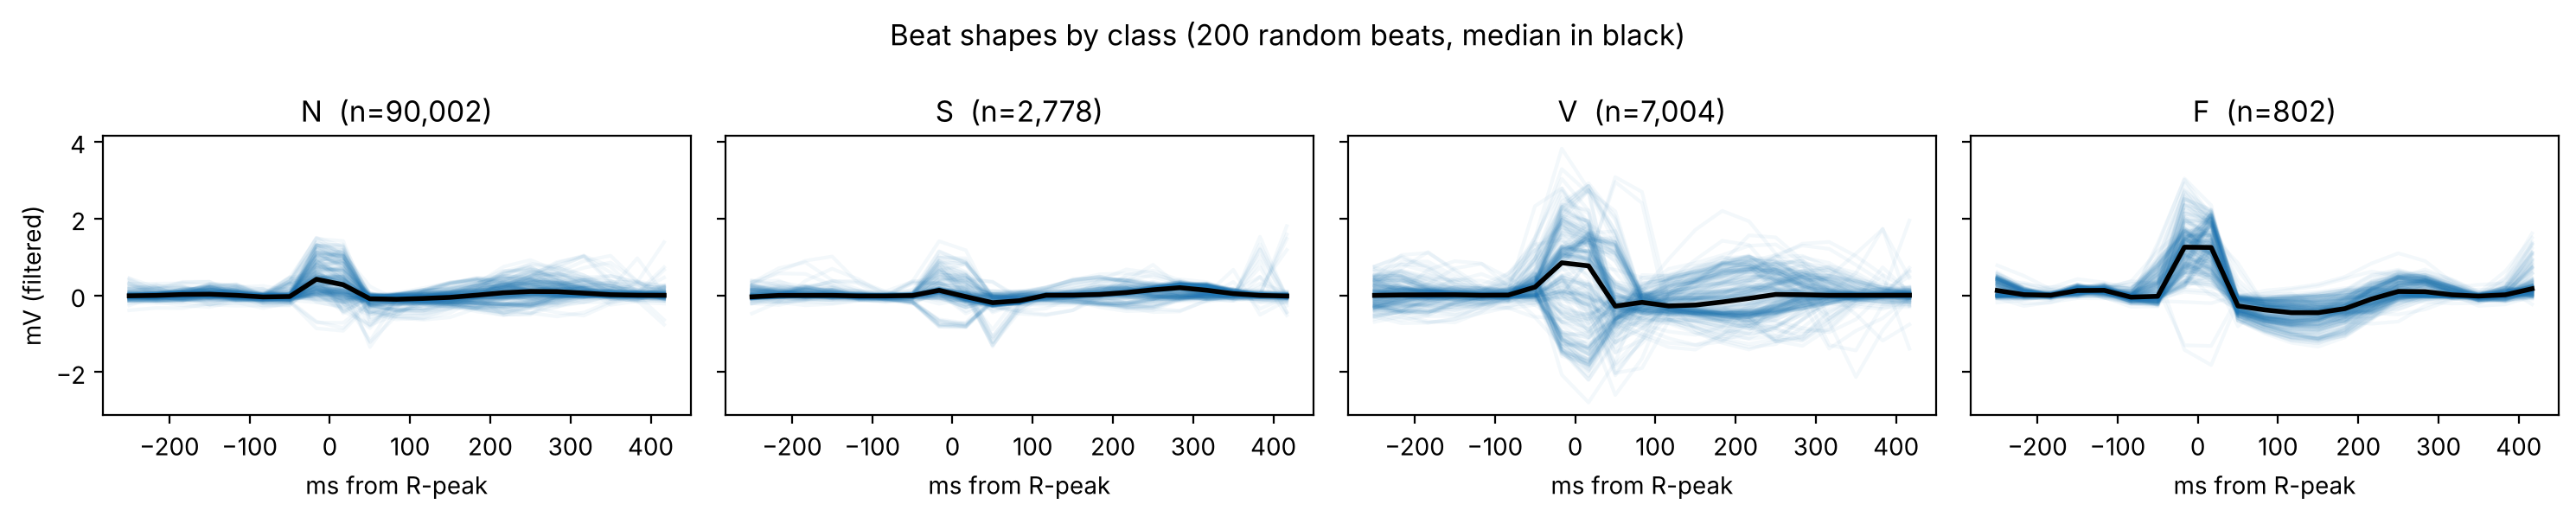

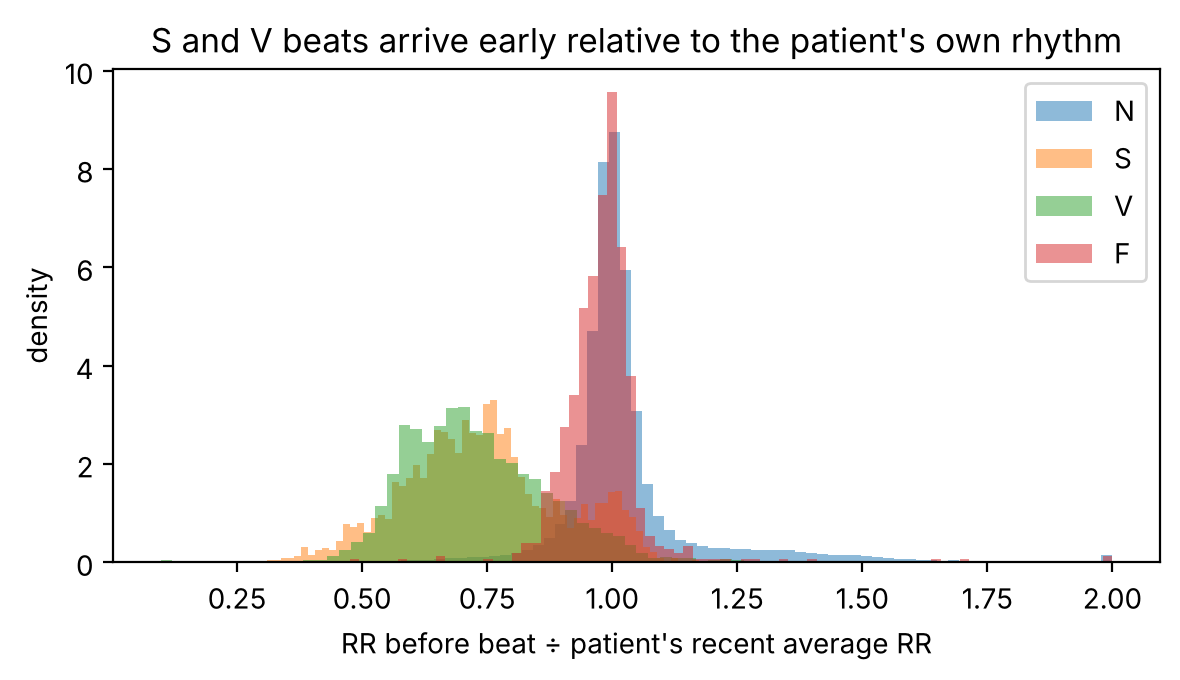

In [4]:
beats = beats[beats.label.isin(CLASSES)].reset_index(drop=True)
RR_COLS = ["pre_rr", "post_rr", "local_rr", "long_rr", "pre_local", "pre_long", "post_pre", "post_local"]
SHAPE_COLS = ["r_amp", "w_min", "w_max", "qrs_energy", "abs_slope_max"]
WAVE_COLS = [c for c in beats.columns if c.startswith("w") and c[1:].isdigit()]
FEATS = RR_COLS + SHAPE_COLS + WAVE_COLS

fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
t = (np.arange(len(WAVE_COLS)) * STEP - PRE) / FS * 1000
for ax, c in zip(axes, CLASSES):
    sub = beats[beats.label == c].sample(min(200, (beats.label == c).sum()), random_state=RNG)
    ax.plot(t, sub[WAVE_COLS].T.values, color="tab:blue", alpha=0.05)
    ax.plot(t, sub[WAVE_COLS].median().values, color="k", lw=2)
    ax.set_title(f"{c}  (n={(beats.label == c).sum():,})"); ax.set_xlabel("ms from R-peak")
axes[0].set_ylabel("mV (filtered)")
plt.suptitle("Beat shapes by class (200 random beats, median in black)"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.5))
for c in CLASSES:
    ax.hist(beats.loc[beats.label == c, "pre_local"].clip(0, 2), bins=80, density=True, alpha=0.5, label=c)
ax.set_xlabel("RR before beat ÷ patient's recent average RR"); ax.set_ylabel("density"); ax.legend()
ax.set_title("S and V beats arrive early relative to the patient's own rhythm"); plt.tight_layout(); plt.show()

## 3. Evaluation helpers

AAMI EC57 reports, per class, **sensitivity** (recall: what share of real S beats we caught)
and **PPV** (precision: when we say S, how often we are right). We summarise with
**macro-F1**, which weights every class equally so that the rare classes count.

In [5]:
def report(y_true, y_pred, title=""):
    p, r, f, n = precision_recall_fscore_support(y_true, y_pred, labels=CLASSES, zero_division=0)
    tab = pd.DataFrame({"Sensitivity": r, "PPV": p, "F1": f, "Support": n}, index=CLASSES)
    acc = (np.asarray(y_true) == np.asarray(y_pred)).mean()
    print(f"{title}\n  accuracy={acc:.3f}   macro-F1={f.mean():.3f}")
    return tab.round(3)


def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, f"{cm[i, j]:,}\n{cmn[i, j]:.0%}", ha="center", va="center",
                    color="white" if cmn[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(4), CLASSES); ax.set_yticks(range(4), CLASSES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title); plt.tight_layout(); plt.show()


train = beats[beats.record.isin(DS1)]
test = beats[beats.record.isin(DS2)]
Xtr, ytr, gtr = train[FEATS], train.label.values, train.record.values
Xte, yte = test[FEATS], test.label.values

## 4. Why the split matters: the leakage experiment

Same features, same model, two ways of splitting:
* **Random beat split**: shuffle all beats, 80/20. This mimics the Kaggle CSVs.
* **Patient split**: train on DS1 patients, test on new DS2 patients.

The model is a plain gradient-boosted tree with default settings, so the only thing that
changes is the split.

In [6]:
def quick_gbm(X, y):
    m = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=RNG, verbose=-1)
    return m.fit(X, y)

Xa, Xb, ya, yb = train_test_split(beats[FEATS], beats.label, test_size=0.2, stratify=beats.label, random_state=RNG)
leaky = report(yb, quick_gbm(Xa, ya).predict(Xb), "Random beat split (patients leak across train/test)")
honest = report(yte, quick_gbm(Xtr, ytr).predict(Xte), "Patient split (DS1 -> DS2)")
majority = report(yte, np.full(len(yte), "N"), "Always predict N (DS2)")
pd.concat({"Random split": leaky, "Patient split": honest, "Always N": majority}, axis=1)

Random beat split (patients leak across train/test)
  accuracy=0.995   macro-F1=0.946


Patient split (DS1 -> DS2)
  accuracy=0.919   macro-F1=0.548
Always predict N (DS2)
  accuracy=0.890   macro-F1=0.236


Random split                       Patient split                        \
   Sensitivity    PPV     F1 Support   Sensitivity    PPV     F1 Support   
N        0.999  0.997  0.998   18001         0.954  0.964  0.959   44197   
S        0.955  0.974  0.965     556         0.131  0.340  0.189    1835   
V        0.979  0.986  0.982    1401         0.944  0.796  0.864    3219   
F        0.781  0.906  0.839     160         0.410  0.117  0.182     388   

     Always N                       
  Sensitivity   PPV     F1 Support  
N         1.0  0.89  0.942   44197  
S         0.0  0.00  0.000    1835  
V         0.0  0.00  0.000    3219  
F         0.0  0.00  0.000     388

The random split looks close to perfect. On new patients the same model falls apart on the
classes that matter. S and F beats in particular are found far less often. Meanwhile
"always N" still gets about 90% accuracy. **A model's score on a random split says almost
nothing about how it will perform on the next patient.** Everything from here uses the
patient split only.

## 5. Model selection with patient-grouped cross-validation (DS1 only)

We compare a simple, interpretable **baseline** (multinomial logistic regression) with
**LightGBM** (gradient-boosted trees). For both we try with and without class re-weighting,
which counters the imbalance by making mistakes on rare classes cost more.

`GroupKFold` keeps every beat of a patient in the same fold, so each validation fold is
made of unseen patients, just like the real test. DS2 is not used here.

In [7]:
def make_model(kind, balanced):
    if kind == "logreg":
        return make_pipeline(StandardScaler(),
                             LogisticRegression(max_iter=2000, C=0.1,
                                                class_weight="balanced" if balanced else None))
    return lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=50,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
                              class_weight="balanced" if balanced else None,
                              random_state=RNG, verbose=-1)


CANDIDATES = {
    "LogReg": ("logreg", False),
    "LogReg + class weights": ("logreg", True),
    "LightGBM": ("lgbm", False),
    "LightGBM + class weights": ("lgbm", True),
}
FEATURE_SETS = {"RR only": RR_COLS, "Morphology only": SHAPE_COLS + WAVE_COLS, "RR + morphology": FEATS}

gkf = GroupKFold(n_splits=5)
cv_rows = []
for fs_name, cols in FEATURE_SETS.items():
    for name, (kind, bal) in CANDIDATES.items():
        if fs_name != "RR + morphology" and name != "LightGBM + class weights":
            continue  # feature-set ablation only for the main model, to keep run time short
        oof = np.empty(len(ytr), dtype=object)
        for tr_i, va_i in gkf.split(Xtr, ytr, gtr):
            m = make_model(kind, bal).fit(Xtr.iloc[tr_i][cols], ytr[tr_i])
            oof[va_i] = m.predict(Xtr.iloc[va_i][cols])
        p, r, f, _ = precision_recall_fscore_support(ytr, oof, labels=CLASSES, zero_division=0)
        cv_rows.append({"features": fs_name, "model": name, "macro-F1": f.mean(),
                        **{f"Se {c}": r[i] for i, c in enumerate(CLASSES)},
                        **{f"PPV {c}": p[i] for i, c in enumerate(CLASSES)}})
cv = pd.DataFrame(cv_rows).sort_values("macro-F1", ascending=False).round(3)
cv

,features,model,macro-F1,Se N,Se S,Se V,Se F,PPV N,PPV S,PPV V,PPV F
5,RR + morphology,LightGBM + class weights,0.461,0.904,0.259,0.894,0.000,0.977,0.284,0.494,0.000
4,RR + morphology,LightGBM,0.457,0.936,0.175,0.853,0.000,0.971,0.279,0.541,0.000
0,RR only,LightGBM + class weights,0.405,0.927,0.198,0.568,0.000,0.974,0.096,0.519,0.000
3,RR + morphology,LogReg + class weights,0.386,0.734,0.510,0.742,0.164,0.976,0.145,0.327,0.015
2,RR + morphology,LogReg,0.380,0.878,0.142,0.631,0.000,0.946,0.269,0.319,0.000
1,Morphology only,LightGBM + class weights,0.353,0.764,0.146,0.917,0.012,0.967,0.044,0.331,0.004


Things to read from this table:
* **Class weighting** raises sensitivity for the rare classes at some cost in PPV. In a
  screening setting a missed arrhythmia costs more than a false alarm a clinician can dismiss,
  so we accept that trade.
* **RR features and morphology are complementary.** RR timing carries most of the S signal,
  while shape carries V. Neither alone matches the combination.
* The validation folds contain only 4–5 patients each, so these numbers are noisy. We prefer
  the simplest model that is clearly competitive, rather than chasing the third decimal place.

We pick the model with the best grouped-CV macro-F1 and refit it on all of DS1.

In [8]:
best = cv[cv.features == "RR + morphology"].iloc[0]
print("Selected:", best.model)
final = make_model(*CANDIDATES[best.model]).fit(Xtr, ytr)

Selected: LightGBM + class weights


## 6. Final evaluation on unseen patients (DS2, used once)

LightGBM + class weights on DS2 (22 unseen patients)
  accuracy=0.868   macro-F1=0.533


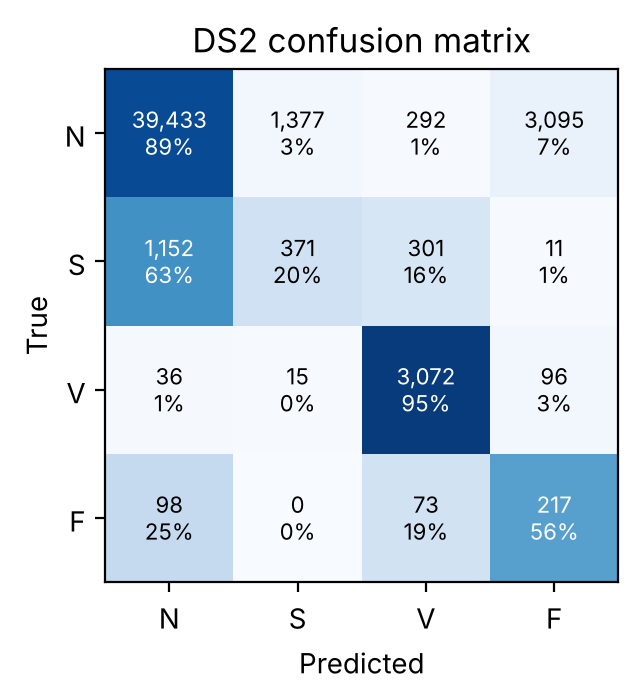

,Sensitivity,PPV,F1,Support
N,0.892,0.968,0.929,44197
S,0.202,0.210,0.206,1835
V,0.954,0.822,0.883,3219
F,0.559,0.063,0.114,388


In [9]:
pred = final.predict(Xte)
display_tab = report(yte, pred, f"{best.model} on DS2 (22 unseen patients)")
plot_cm(yte, pred, "DS2 confusion matrix")
display_tab

### How stable is that number? Patient-level bootstrap

A single test score hides how much it depends on *which* 22 patients happened to be in the
test set. Resampling **patients** (not beats) with replacement gives a realistic 95% interval.

In [10]:
rng = np.random.default_rng(RNG)
test_recs = np.array(DS2)
res = pd.DataFrame({"record": test.record.values, "y": yte, "p": pred})
by_rec = {r: g for r, g in res.groupby("record")}
boot = []
for _ in range(500):
    g = pd.concat([by_rec[r] for r in rng.choice(test_recs, len(test_recs), replace=True)])
    p, r, f, _ = precision_recall_fscore_support(g.y, g.p, labels=CLASSES, zero_division=0)
    boot.append({"macro-F1": f.mean(), **{f"Se {c}": r[i] for i, c in enumerate(CLASSES)},
                 **{f"PPV {c}": p[i] for i, c in enumerate(CLASSES)}})
boot = pd.DataFrame(boot)
boot.quantile([0.025, 0.5, 0.975]).T.round(3).rename(columns={0.025: "2.5%", 0.5: "median", 0.975: "97.5%"})

,2.5%,median,97.5%
macro-F1,0.459,0.535,0.638
Se N,0.792,0.895,0.961
Se S,0.054,0.255,0.857
Se V,0.844,0.959,0.994
Se F,0.000,0.555,0.588
PPV N,0.913,0.970,0.999
PPV S,0.083,0.216,0.387
PPV V,0.558,0.827,0.936
PPV F,0.000,0.055,0.380


### Where does it fail? Per-patient view

Pooled metrics can be dominated by one or two patients with thousands of ectopic beats.
Looking per patient shows whether errors are spread out or concentrated.

In [11]:
per_rec = []
for r_id, g in res.groupby("record"):
    row = {"record": r_id, "beats": len(g)}
    for c in ["S", "V"]:
        n = (g.y == c).sum()
        row[f"{c} beats"] = n
        row[f"Se {c}"] = ((g.y == c) & (g.p == c)).sum() / n if n else np.nan
        row[f"false {c} alarms"] = ((g.y != c) & (g.p == c)).sum()
    per_rec.append(row)
per_rec = pd.DataFrame(per_rec).set_index("record")
per_rec.sort_values("S beats", ascending=False).round(2)

,beats,S beats,Se S,false S alarms,V beats,Se V,false V alarms
record,,,,,,,
232,1777,1380,0.02,0,0,NaN,256
222,2480,209,0.87,374,0,NaN,34
202,2133,55,0.82,139,19,0.95,8
234,2750,50,0.60,1,3,1.00,0
100,2270,33,1.00,2,1,1.00,0
200,2598,30,0.77,16,825,0.99,1
213,3248,28,0.00,0,220,0.56,124
210,2647,22,0.77,156,195,0.86,18
233,3076,7,0.29,0,830,1.00,34


**One patient decides the pooled S score.** Record 232 alone holds about 75% of all S beats
in the test set, and the model misses almost all of them. Record 232 is a slow (bradycardic)
rhythm in which S beats are the *majority* of beats. Our RR features describe a beat as
"early compared with this patient's recent average", but when most recent beats are S beats,
the average itself is made of S beats and nothing looks early. That is a genuine
failure mode of the feature design, not bad luck.

The cell below is **only a diagnostic**. We do not use it to change the model, because
changing the model after looking at the test set would leak the test set into the design.

In [12]:
mask = res.record != 232
print(report(res.y[mask], res.p[mask], "DS2 excluding record 232 (diagnostic only)").loc[["S"]])

DS2 excluding record 232 (diagnostic only)
  accuracy=0.892   macro-F1=0.572
   Sensitivity  PPV     F1  Support
S        0.765  0.2  0.317      455


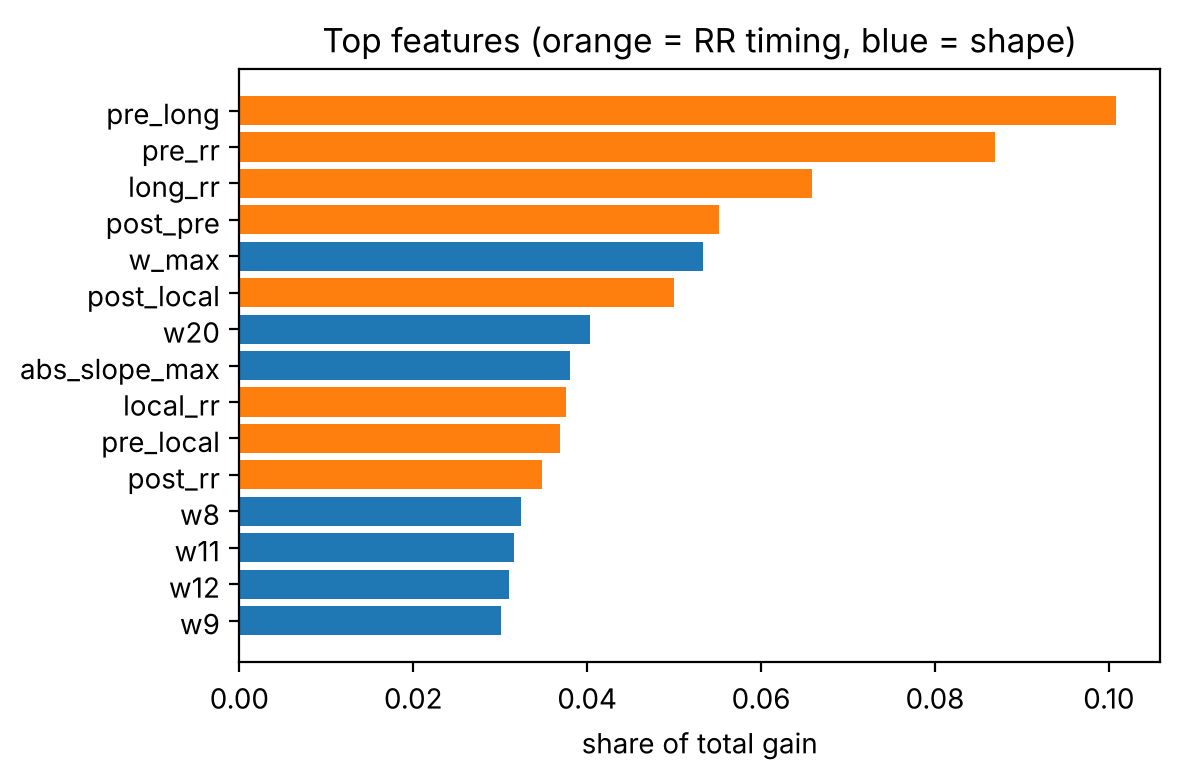

In [13]:
imp = pd.Series(final.booster_.feature_importance("gain"), index=FEATS) if hasattr(final, "booster_") else None
if imp is not None:
    top = (imp / imp.sum()).sort_values(ascending=False).head(15)[::-1]
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.barh(top.index, top.values, color=["tab:orange" if c in RR_COLS else "tab:blue" for c in top.index])
    ax.set_xlabel("share of total gain"); ax.set_title("Top features (orange = RR timing, blue = shape)")
    plt.tight_layout(); plt.show()

## 7. Conclusions and limitations

**What we can claim**
* **Patient-wise evaluation changes the conclusion entirely.** The same model scores about
  0.95 macro-F1 on a random beat split and about 0.55 on new patients. Any result on the
  Kaggle `mitbih_train/test` CSVs should be read as an *intra-patient* result.
* On patients it never saw, the model detects about 95% of V beats with a PPV of about 0.8.
* S detection is the weak point. Pooled sensitivity is low because one test patient (232)
  contains most of the S beats, in a rhythm that our "early relative to recent average"
  features cannot describe. On the other 21 patients, S sensitivity is about 77%, close to
  de Chazal's 76%, but PPV is only about 0.20 (theirs was 0.38), so false S alarms are the next problem. The bootstrap interval for Se S (roughly 5% to 85%)
  reflects exactly this dependence on which patients are in the test set.
* Model selection was honest. Grouped CV chose the class-weighted LightGBM. Its DS2 macro-F1
  came out slightly *below* the unweighted model in section 4, and we report it anyway.
  Swapping models after seeing the test result would quietly turn DS2 into a validation set.

**Limitations, and what a next iteration would address**
0. **RR normalisation for S-dominated rhythms** (record 232). Normalise against the median
   RR of beats with a *normal-looking* morphology, or add rhythm-level context features.
   Validate this on DS1 with grouped CV and on an external database, not on DS2.
1. **R-peaks come from the expert annotations.** A real system needs a QRS detector, and its
   errors would propagate. Next step: run a detector (e.g. Pan-Tompkins) and match detected
   beats to annotations within ±150 ms, as EC57 specifies.
2. **Small test population (22 patients).** The bootstrap interval is wide. External
   validation on another database (INCART, MIT-BIH Supraventricular, which are in Chelsea's
   file list) is the honest next test of generalisation. The same `record_features` function
   works on them after resampling to 360 Hz.
3. **F class.** F beats are a blend of N and V by definition and occur mostly in one training
   patient (208), so the model cannot learn them robustly.
4. **Single lead.** MLII only. A second lead often helps S/V discrimination.
5. **Threshold choice.** We used argmax. In practice one would pick per-class decision
   thresholds on DS1 grouped-CV to hit a target sensitivity, for example Se(V) ≥ 90%.

**Reference**: de Chazal P., O'Dwyer M., Reilly R.B. *Automatic classification of heartbeats
using ECG morphology and heartbeat interval features.* IEEE Trans. Biomed. Eng. 51(7), 2004.
Data: Moody & Mark, MIT-BIH Arrhythmia Database, PhysioNet.